In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
%cd /content/drive/MyDrive/tb

/content/drive/MyDrive/tb


In [3]:
from tensorflow import lite
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import pandas as pd
import random, os
import shutil
import matplotlib.pyplot as plt
from matplotlib.image import imread
from keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.metrics import categorical_accuracy
from sklearn.model_selection import train_test_split

In [4]:
# Add an additional column, mapping to the type
df = pd.read_csv(r'archive/output.csv')

diagnosis_dict_binary = {
    0: 'NO_TB',
    1: 'TB'
}

diagnosis_dict = {
    0: 'Normal',
    1: 'Tuberculosis'
}


df['binary_type'] =  df['type'].map(diagnosis_dict_binary.get)
df['type'] = df['type'].map(diagnosis_dict.get)
df.head()

,id_code,type,binary_type
0,Normal-1,Normal,NO_TB
1,Normal-10,Normal,NO_TB
2,Normal-100,Normal,NO_TB
3,Normal-1000,Normal,NO_TB
4,Normal-1001,Normal,NO_TB


<Axes: >

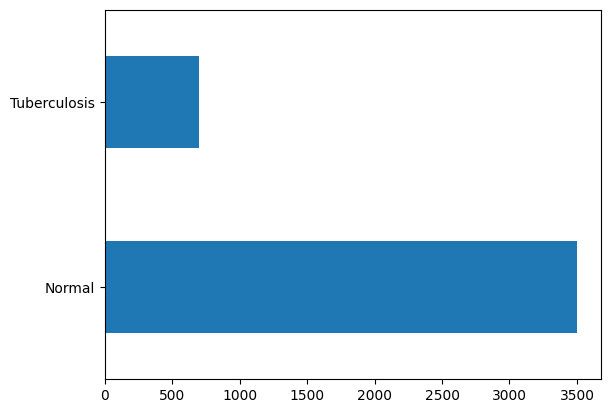

In [5]:
df['type'].value_counts().plot(kind='barh')

<Axes: >

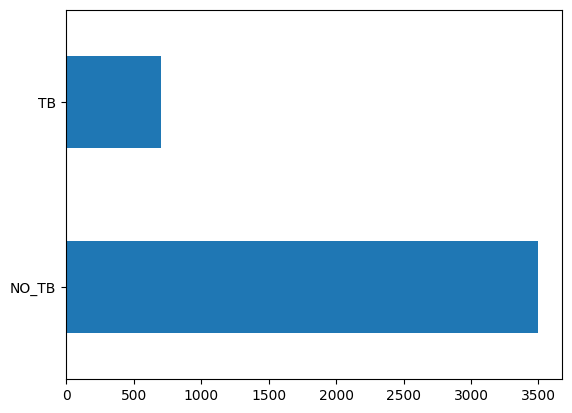

In [6]:
df['binary_type'].value_counts().plot(kind='barh')

In [7]:
# Split into stratified train, val, and test sets
train_intermediate, val = train_test_split(df, test_size = 0.15, stratify = df['type'])
train, test = train_test_split(train_intermediate, test_size = 0.15 / (1 - 0.15), stratify = train_intermediate['type'])

print(train['type'].value_counts(), '\n')
print(test['type'].value_counts(), '\n')
print(val['type'].value_counts(), '\n')

Normal          2450
Tuberculosis     490
Name: type, dtype: int64 

Normal          525
Tuberculosis    105
Name: type, dtype: int64 

Normal          525
Tuberculosis    105
Name: type, dtype: int64 



In [8]:
# Create working directories for train/val/test
base_dir = ''

train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

if os.path.exists(base_dir):
    shutil.rmtree(base_dir)

if os.path.exists(train_dir):
    shutil.rmtree(train_dir)
os.makedirs(train_dir)

if os.path.exists(val_dir):
    shutil.rmtree(val_dir)
os.makedirs(val_dir)

if os.path.exists(test_dir):
    shutil.rmtree(test_dir)
os.makedirs(test_dir)

In [9]:
# Copy images to respective working directory
src_dir = r'archive'
for index, row in train.iterrows():
    diagnosis = row['type']
    binary_diagnosis = row['binary_type']
    id_code = row['id_code'] + ".png"
    srcfile = os.path.join(src_dir, diagnosis, id_code)
    dstfile = os.path.join(train_dir, binary_diagnosis)
    os.makedirs(dstfile, exist_ok = True)
    shutil.copy(srcfile, dstfile)

for index, row in val.iterrows():
    diagnosis = row['type']
    binary_diagnosis = row['binary_type']
    id_code = row['id_code'] + ".png"
    srcfile = os.path.join(src_dir, diagnosis, id_code)
    dstfile = os.path.join(val_dir, binary_diagnosis)
    os.makedirs(dstfile, exist_ok = True)
    shutil.copy(srcfile, dstfile)
 
for index, row in test.iterrows():
    diagnosis = row['type']
    binary_diagnosis = row['binary_type']
    id_code = row['id_code'] + ".png"
    srcfile = os.path.join(src_dir, diagnosis, id_code)
    dstfile = os.path.join(test_dir, binary_diagnosis)
    os.makedirs(dstfile, exist_ok = True)
    shutil.copy(srcfile, dstfile)

In [10]:
# Setting up ImageDataGenerator for train/val/test 

train_path = 'train'
val_path = 'val'
test_path = 'test'

train_batches = ImageDataGenerator(rescale = 1./255).flow_from_directory(train_path, target_size=(224,224), shuffle = True)
val_batches = ImageDataGenerator(rescale = 1./255).flow_from_directory(val_path, target_size=(224,224), shuffle = True)
test_batches = ImageDataGenerator(rescale = 1./255).flow_from_directory(test_path, target_size=(224,224), shuffle = False)

Found 2940 images belonging to 2 classes.
Found 630 images belonging to 2 classes.
Found 630 images belonging to 2 classes.


In [11]:
# Building the model

model = tf.keras.Sequential([
    layers.Conv2D(8, (3,3), padding="valid", input_shape=(224,224,3), activation = 'relu'),
    layers.MaxPooling2D(pool_size=(2,2)),
    layers.BatchNormalization(),
    
    layers.Conv2D(16, (3,3), padding="valid", activation = 'relu'),
    layers.MaxPooling2D(pool_size=(2,2)),
    layers.BatchNormalization(),
    
    layers.Conv2D(32, (4,4), padding="valid", activation = 'relu'),
    layers.MaxPooling2D(pool_size=(2,2)),
    layers.BatchNormalization(),
 
    layers.Flatten(),
    layers.Dense(32, activation = 'relu'),
    layers.Dropout(0.15),
    layers.Dense(2, activation = 'softmax')
])

model.compile(optimizer=tf.keras.optimizers.Adam(lr = 1e-5),
              loss=tf.keras.losses.BinaryCrossentropy(),
              metrics=['acc'])

history = model.fit(train_batches,
                    epochs=30,
                    validation_data=val_batches)

Epoch 1/30
92/92 [==============================] - 52s 488ms/step - loss: 0.1990 - acc: 0.9497 - val_loss: 3.2820 - val_acc: 0.1667
Epoch 2/30
92/92 [==============================] - 41s 446ms/step - loss: 0.0713 - acc: 0.9796 - val_loss: 3.3540 - val_acc: 0.1873
Epoch 3/30
92/92 [==============================] - 41s 447ms/step - loss: 0.0489 - acc: 0.9861 - val_loss: 2.7096 - val_acc: 0.3603
Epoch 4/30
92/92 [==============================] - 41s 443ms/step - loss: 0.0229 - acc: 0.9935 - val_loss: 4.4573 - val_acc: 0.3444
Epoch 5/30
92/92 [==============================] - 40s 439ms/step - loss: 0.0179 - acc: 0.9925 - val_loss: 1.4526 - val_acc: 0.5667
Epoch 6/30
92/92 [==============================] - 41s 444ms/step - loss: 0.0291 - acc: 0.9895 - val_loss: 0.1301 - val_acc: 0.9635
Epoch 7/30
92/92 [==============================] - 42s 454ms/step - loss: 0.0195 - acc: 0.9925 - val_loss: 0.0735 - val_acc: 0.9810
Epoch 8/30
92/92 [==============================] - 41s 447ms/step - 

In [12]:
model.save('64x3-CNN.model')

In [13]:
loss, acc = model.evaluate_generator(test_batches, verbose=1)
# print("Loss: ", loss)
print("Accuracy: ", acc)

<ipython-input-13-f081ff5ff9c3>:1: UserWarning: `Model.evaluate_generator` is deprecated and will be removed in a future version. Please use `Model.evaluate`, which supports generators.
  loss, acc = model.evaluate_generator(test_batches, verbose=1)


20/20 [==============================] - 6s 296ms/step - loss: 0.1679 - acc: 0.9889
Accuracy:  0.9888888597488403


In [14]:
import cv2

In [15]:
def predict_class(path):
    img = cv2.imread(path)

    RGBImg = cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
    RGBImg= cv2.resize(RGBImg,(224,224))
    plt.imshow(RGBImg)
    image = np.array(RGBImg) / 255.0
    new_model = tf.keras.models.load_model("64x3-CNN.model")
    predict=new_model.predict(np.array([image]))
    per=np.argmax(predict,axis=1)
    if per==1:
        print('Tuberculosis')
    else:
        print('Normal')

1/1 [==============================] - 0s 205ms/step
Normal


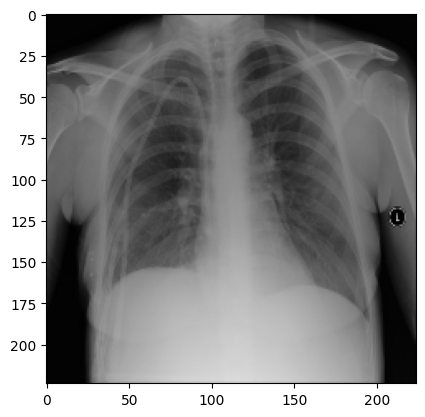

In [16]:
predict_class('archive/Normal/Normal-1.png')

1/1 [==============================] - 0s 107ms/step
Tuberculosis


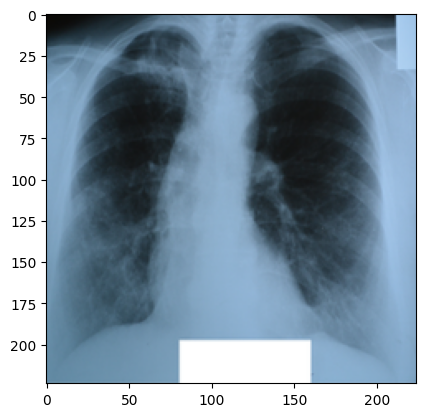

In [17]:
predict_class('archive/Tuberculosis/Tuberculosis-1.png')